# 04 - Aplicação estratégica: onde agir?

Este notebook transforma os modelos em **inteligência para o gestor público** e responde às
três perguntas de negócio que faltam:

1. **Como prever municípios que podem não atingir metas futuras?** Modelo de metas, com previsão
   conservadora para 2025 (cenário completo + cenário neutro nos estados com choque atípico).
2. **Quais municípios apresentam maior risco educacional?** Índice de risco e ranking.
3. **Quais regiões possuem padrões semelhantes?** Clusterização por contexto.

Unidade de análise: a **rede municipal** de cada município, que é a rede responsável pela maior
parte da alfabetização e a que tem metas municipais oficiais.

Arquivos gerados para uso dos gestores (pasta `reports/`):
- `previsao_meta_2025.csv`
- `ranking_risco_municipios_2024.csv`
- `clusters_municipios.csv`

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import DIR_REPORTS
from src.modeling import clusterizacao as cl, modelo_metas as mm, risco
from src.modeling.base_municipal import carregar_base_municipal
from src.visualization import graficos as g

g.configurar_estilo()
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. Quem pode não atingir as metas futuras?

**Desenho:** o modelo aprende a transição "ano atual → ano seguinte".
- **Treino:** situação em 2023 (taxa, meta de 2024, contexto) → a rede **atingiu a meta de 2024**?
- **Previsão:** situação em 2024 (taxa, meta de 2025, contexto) → vai **atingir a meta de 2025**?

Features: taxa atual, meta do ano seguinte, distância até a meta, tamanho da rede (log de alunos)
e as 47 variáveis de contexto, mais UF e região. Todas são conhecidas antes do ano previsto.

In [2]:
treino_metas = mm.base_transicao(2023)
treino_metas = treino_metas[treino_metas[mm.ALVO].notna()].reset_index(drop=True)
futuro = mm.base_transicao(2024)
print(f"treino (2023 -> 2024): {len(treino_metas):,} redes municipais | "
      f"{treino_metas[mm.ALVO].astype(int).mean():.1%} atingiram a meta de 2024")
print(f"previsão (2024 -> 2025): {len(futuro):,} redes municipais")

avaliacao, _ = mm.avaliar(treino_metas)
avaliacao

treino (2023 -> 2024): 4,611 redes municipais | 53.6% atingiram a meta de 2024
previsão (2024 -> 2025): 5,352 redes municipais


,AUC (estratificado),AUC (por UF),Brier
modelo,,,
regra: já está acima da meta,0.50,0.50,NaN
logística,0.80,0.56,0.18
LightGBM,0.81,0.59,0.18


**Leitura:**
- **A regra ingênua não funciona** (AUC 0,50): estar acima da meta hoje não garante continuar acima no ano seguinte. Isso é a regressão à média vista na EDA. Muitas redes pequenas com taxa alta caem, e as com taxa baixa sobem.
- **O LightGBM chega a 0,81** quando prevê municípios novos de estados conhecidos (validação estratificada). Ele combina a distância até a meta, o tamanho da rede (quanto ruído esperar) e o contexto.
- **Para estados nunca vistos** (validação por UF), o AUC cai para 0,59. Boa parte do que decide se uma rede bate a meta é **comum ao estado naquele ano**: políticas, calendário, choques como as enchentes no RS.
- **O desempenho real** de uma previsão para o ano seguinte deve ficar **entre esses dois valores**. O modelo é útil para priorizar, não para cravar o resultado de um município.

### Sensibilidade: quanto a previsão depende do território?

,AUC (estratificado),AUC (por UF),% previsto de atingir 2025,prob. média RS,prob. média BA,prob. média CE,prob. média SP
com UF e região,0.81,0.59,55.17,0.16,0.19,0.89,0.82
só região,0.78,0.56,56.04,0.27,0.32,0.84,0.86
sem UF/região,0.76,0.53,55.06,0.34,0.32,0.84,0.78


,AUC (estratificado),AUC (por UF),Brier
cenário neutro (só situação da rede),0.61,0.47,0.24


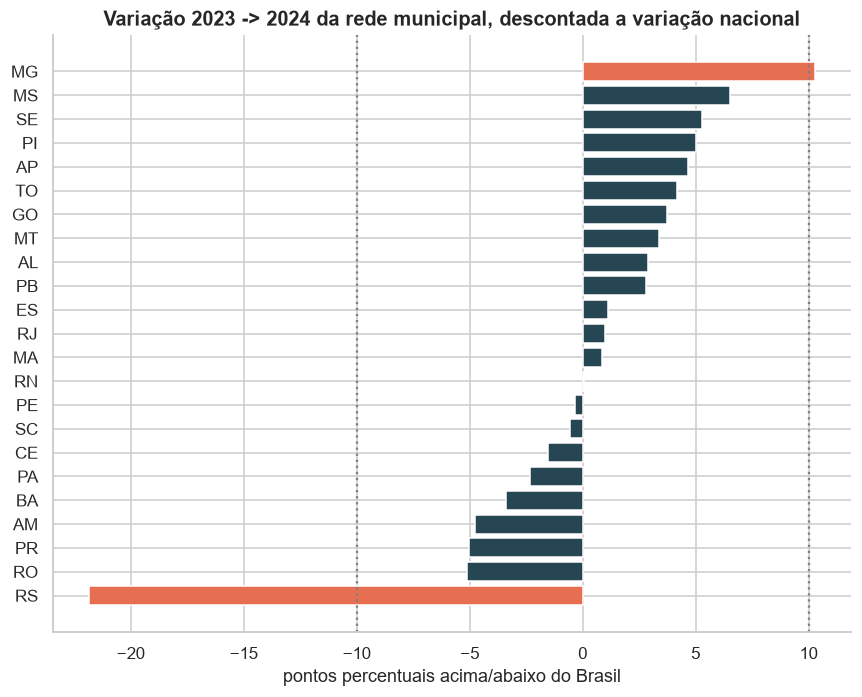

In [3]:
sensibilidade = mm.sensibilidade_territorio(treino_metas, futuro)
neutro = pd.Series(mm.avaliar_cenario_neutro(treino_metas), name="cenário neutro (só situação da rede)")
display(sensibilidade.round(2))
display(neutro.to_frame().T.round(3))

choques = mm.choques_estaduais(treino_metas).sort_values()
cores = np.where(choques.abs() > mm.LIMITE_CHOQUE_PP, g.COR_DESTAQUE, g.COR_PRINCIPAL)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(choques.index, choques.values, color=cores)
for limite in (-mm.LIMITE_CHOQUE_PP, mm.LIMITE_CHOQUE_PP):
    ax.axvline(limite, color="grey", linestyle=":")
ax.set(title="Variação 2023 -> 2024 da rede municipal, descontada a variação nacional",
       xlabel="pontos percentuais acima/abaixo do Brasil")
fig.tight_layout()
fig.savefig(g.DIR_IMAGENS / "app_00_choques_estaduais.png")
plt.show()

**Leitura - por que a previsão de 2025 precisa de um tratamento conservador:**
- **Tirar a UF não resolve.** Mesmo sem UF e região, o RS continua com chance de 34%, porque o contexto (ruralidade, IDHM etc.) identifica o "perfil gaúcho". Com **uma única transição de treino** (2023 → 2024), o modelo completo repete o que aconteceu em cada estado naquele ano.
- **O RS foi um choque atípico:** a rede municipal caiu **~22 pontos além da variação nacional**, no ano das enchentes. Nenhum outro estado passou de ±7 pontos, exceto Minas Gerais (+10, choque positivo).
- **O cenário neutro** usa só a situação da rede (taxa, meta, distância, tamanho) e capta a dinâmica nacional de regressão à média. Sozinho, ele é fraco (AUC 0,61), mas não carrega padrões regionais.

**Regra adotada para a previsão publicada:**
- **Choque atípico:** nos estados cuja variação no ano de treino se afastou da nacional em **mais de 10 pontos** (RS e MG), publica-se o **cenário neutro**, com confiança baixa.
- **Sem histórico:** estados sem rede municipal avaliada em 2023 (SP e AC) ficam com o cenário completo, mas com **confiança baixa**.
- **Demais estados:** cenário completo, o mais bem validado.

Assim, um evento extraordinário não vira tendência. O exemplo é Nova Santa Rita (RS), que **já está acima da meta de 2025**: tinha 4% de chance no modelo completo e passa a ter 38% no cenário neutro.

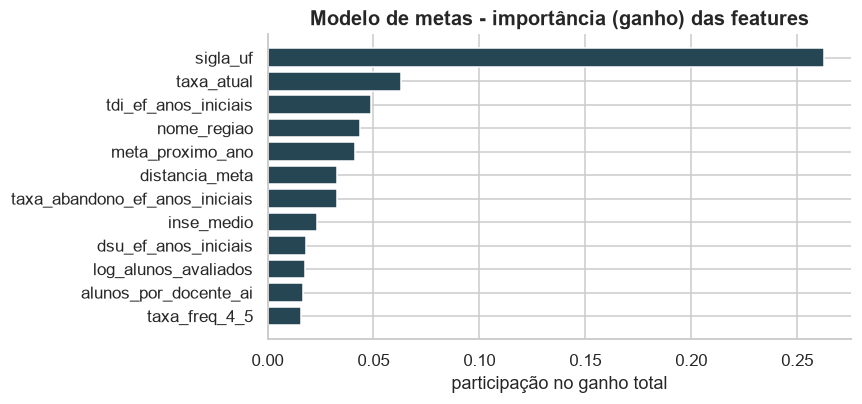

In [4]:
pipeline_metas, _ = mm.treinar_e_prever(treino_metas, futuro)
cenarios = mm.prever_com_cenarios(treino_metas, futuro)
futuro = futuro.join(cenarios)
futuro["proba_atingir_meta_2025"] = futuro["proba_atingir_meta"]

nomes_features = pipeline_metas.named_steps["prep"].get_feature_names_out()
importancia = (
    pd.Series(pipeline_metas.named_steps["modelo"].booster_.feature_importance("gain"), index=nomes_features)
    .groupby(lambda n: n.removeprefix("missingindicator_").split("_")[0] + "_" + n.removeprefix("missingindicator_").split("_")[1]
             if n.startswith(("sigla_uf", "nome_regiao")) else n.removeprefix("missingindicator_"))
    .sum()
)
importancia = (importancia / importancia.sum()).sort_values(ascending=False)
from src.evaluation.interpretabilidade import grafico_barras
grafico_barras(importancia, top=12, titulo="Modelo de metas - importância (ganho) das features",
               xlabel="participação no ganho total", salvar="app_01_importancia_metas");

In [5]:
previsao_uf = futuro.groupby("sigla_uf").agg(
    redes=("id_municipio", "size"),
    prob_media_atingir=("proba_atingir_meta_2025", "mean"),
    redes_em_risco=("proba_atingir_meta_2025", lambda p: (p < 0.4).sum()),
    confianca_baixa=("confianca", lambda c: (c != "normal").sum()),
).sort_values("prob_media_atingir")
print("confiança da previsão:")
print(futuro["confianca"].value_counts().to_string())
print(f"redes com baixa chance (< 40%) de atingir a meta de 2025: {(futuro['proba_atingir_meta_2025'] < 0.4).sum():,} "
      f"de {len(futuro):,} ({(futuro['proba_atingir_meta_2025'] < 0.4).mean():.0%})")
print(f"número esperado de redes que atingem a meta de 2025: {futuro['proba_atingir_meta_2025'].sum():,.0f} "
      f"({futuro['proba_atingir_meta_2025'].mean():.0%})")
previsao_uf.round(2)

confiança da previsão:
confianca
normal                                                     3445
baixa: UF com choque atípico no treino (cenário neutro)    1259
baixa: UF sem histórico no treino                           648
redes com baixa chance (< 40%) de atingir a meta de 2025: 1,431 de 5,352 (27%)
número esperado de redes que atingem a meta de 2025: 2,913 (54%)


,redes,prob_media_atingir,redes_em_risco,confianca_baixa
sigla_uf,,,,
BA,398,0.19,389,0
PA,142,0.31,111,0
AM,55,0.33,39,0
AC,22,0.37,15,22
AP,16,0.39,8,0
RS,441,0.42,179,441
RJ,92,0.43,39,0
RN,151,0.44,66,0
SE,75,0.47,26,0


In [6]:
colunas_saida = ["id_municipio", "nome_municipio", "sigla_uf", "taxa_atual", "meta_proximo_ano",
                 "distancia_meta", "alunos_avaliados", "proba_cenario_completo", "proba_cenario_neutro",
                 "proba_atingir_meta_2025", "confianca"]
saida_metas = futuro[colunas_saida].rename(columns={"taxa_atual": "taxa_2024", "meta_proximo_ano": "meta_2025",
                                                     "distancia_meta": "distancia_meta_2025"})
saida_metas.sort_values("proba_atingir_meta_2025").to_csv(DIR_REPORTS / "previsao_meta_2025.csv", index=False)
saida_metas[saida_metas["alunos_avaliados"] >= 50].nsmallest(15, "proba_atingir_meta_2025").round(2)

,id_municipio,nome_municipio,sigla_uf,taxa_2024,meta_2025,distancia_meta_2025,alunos_avaliados,proba_cenario_completo,proba_cenario_neutro,proba_atingir_meta_2025,confianca
2077,2925303,Porto Seguro,BA,45.50,57.50,-12.00,2200,0.05,0.20,0.05,normal
2176,2933307,Vitória da Conquista,BA,42.75,58.30,-15.55,2826,0.06,0.17,0.06,normal
1851,2905701,Camaçari,BA,36.56,47.70,-11.14,2552,0.06,0.14,0.06,normal
1910,2910800,Feira de Santana,BA,33.19,46.42,-13.23,3528,0.07,0.15,0.07,normal
1961,2915601,Itamaraju,BA,37.41,55.62,-18.21,556,0.07,0.33,0.07,normal
1975,2917102,Itororó,BA,28.85,57.97,-29.12,104,0.07,0.41,0.07,normal
2151,2931350,Teixeira de Freitas,BA,35.04,61.04,-26.00,1367,0.07,0.19,0.07,normal
1907,2910727,Eunápolis,BA,38.37,48.55,-10.18,787,0.07,0.15,0.07,normal
1821,2903201,Barreiras,BA,36.09,51.14,-15.05,1654,0.07,0.17,0.07,normal
2024,2921104,Medeiros Neto,BA,46.90,60.77,-13.87,226,0.07,0.35,0.07,normal


**Leitura:**
- **Volume esperado:** 54% das redes municipais devem atingir a meta de 2025 (cerca de 2.900 de 5.352). **1.431 redes (27%)** têm chance abaixo de 40%.
- **Bahia:** concentra o maior risco (389 redes, chance média de 19%). Ali **não houve choque atípico**: o risco é estrutural e a previsão tem confiança normal.
- **RS:** com o cenário neutro, a chance média sobe de 16% para 42%, com confiança baixa.
- **Lista completa:** está em `reports/previsao_meta_2025.csv`, com os dois cenários e a coluna `confianca` para cada rede. A tabela acima mostra só redes com 50+ alunos avaliados.

### Validação externa: o que aconteceu de fato em 2025 (nível estadual)

Os resultados municipais de 2025 ainda não foram publicados, mas os **estaduais** sim, na tabela de
metas do Inep. Eles permitem uma checagem aproximada da previsão. A comparação é aproximada porque
o resultado estadual inclui a rede estadual e a municipal, e a previsão é da rede municipal.

In [7]:
from scipy.stats import spearmanr
from src.config import DIR_RAW

metas_uf = pd.read_parquet(DIR_RAW / "meta_alfabetizacao_uf.parquet")
real_uf = metas_uf.pivot_table(index="sigla_uf", columns="ano", values="taxa_alfabetizacao")
meta_uf_2025 = metas_uf.sort_values("ano").drop_duplicates("sigla_uf", keep="last").set_index("sigla_uf")["meta_alfabetizacao_2025"]
validacao = pd.DataFrame({
    "prob. média prevista (redes municipais)": futuro.groupby("sigla_uf")["proba_atingir_meta_2025"].mean(),
    "resultado 2024": real_uf[2024],
    "resultado 2025": real_uf[2025],
    "meta 2025": meta_uf_2025,
}).dropna()
validacao["atingiu meta 2025"] = validacao["resultado 2025"] >= validacao["meta 2025"]
validacao["folga 2025 (p.p.)"] = validacao["resultado 2025"] - validacao["meta 2025"]

rho_folga = spearmanr(validacao["prob. média prevista (redes municipais)"], validacao["folga 2025 (p.p.)"])[0]
rho_atingiu = spearmanr(validacao["prob. média prevista (redes municipais)"], validacao["atingiu meta 2025"])[0]
print(f"UFs comparadas: {len(validacao)}")
print(f"correlação (Spearman) previsão x folga real em relação à meta: {rho_folga:.2f}")
print(f"correlação (Spearman) previsão x atingiu a meta:                {rho_atingiu:.2f}")
print(f"UFs que atingiram a meta 2025: {validacao['atingiu meta 2025'].mean():.0%} | "
      f"probabilidade média prevista: {validacao['prob. média prevista (redes municipais)'].mean():.0%}")
validacao.sort_values("prob. média prevista (redes municipais)").round(2)

UFs comparadas: 25
correlação (Spearman) previsão x folga real em relação à meta: 0.27
correlação (Spearman) previsão x atingiu a meta:                0.43
UFs que atingiram a meta 2025: 76% | probabilidade média prevista: 52%


,prob. média prevista (redes municipais),resultado 2024,resultado 2025,meta 2025,atingiu meta 2025,folga 2025 (p.p.)
sigla_uf,,,,,,
BA,0.19,35.96,55.00,50.00,True,5.00
PA,0.31,48.20,58.00,59.00,False,-1.00
AM,0.33,49.17,57.00,61.00,False,-4.00
AC,0.37,51.38,68.00,57.00,True,11.00
AP,0.39,46.62,60.00,54.00,True,6.00
RS,0.42,44.67,52.00,69.00,False,-17.00
RJ,0.43,55.25,60.00,61.00,False,-1.00
RN,0.44,39.29,48.00,51.00,False,-3.00
SE,0.47,38.39,50.00,46.00,True,4.00


**Leitura - o modelo acerta a direção, mas erra o nível de 2025:**
- **Direção:** a correlação entre a probabilidade prevista e o resultado real é **positiva, mas
  moderada a fraca**: 0,43 com ter atingido a meta e 0,27 com a folga em relação a ela. Estados com previsão alta (CE, GO, ES, MG) de fato bateram a meta. A previsão ordena os
  estados na direção certa, sem muita força.
- **Nível: o modelo foi pessimista.** Ele previu chance média de 52% para as UFs comparadas, mas **76% delas
  bateram a meta de 2025**. O modelo aprendeu com 2023 → 2024, um ano de avanço pequeno, e 2025 trouxe um
  avanço amplo, que nenhuma variável do modelo antecipava.
- **O erro mais relevante é a Bahia:** a menor probabilidade prevista do país (~19%) e o **maior
  salto real** (+19 p.p., batendo a meta estadual). O risco **estrutural** identificado continua
  real (a Bahia segue entre as menores taxas do país), mas a previsão de *não atingir a meta* não se
  confirmou no agregado estadual.
- **Conclusão para o uso:** a previsão de metas serve para **priorizar** (quem está mais longe e
  com contexto mais difícil), **não para afirmar** que uma rede vai ou não bater a meta. Com os
  resultados municipais de 2025, o modelo deve ser retreinado com duas transições, o que deve
  melhorar a calibração do nível.

## 2. Quais municípios apresentam maior risco educacional?

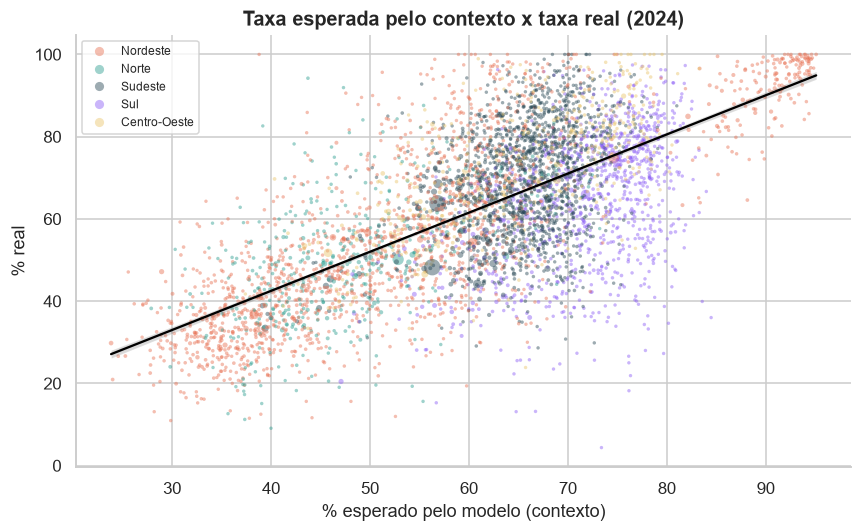

In [8]:
base_2024 = carregar_base_municipal(2024)
proba_meta = base_2024["id_municipio"].map(futuro.set_index("id_municipio")["proba_atingir_meta_2025"])
proba_meta = proba_meta.fillna(proba_meta.median())   # 98 redes sem meta municipal definida
ranking = risco.indice_risco(base_2024, proba_meta)
estaveis = ranking[ranking["alunos_avaliados"] >= 20]   # redes muito pequenas têm taxa instável

g.dispersao_por_regiao(estaveis, "taxa_esperada_contexto", "taxa_alfabetizacao", tamanho="alunos_avaliados",
                       salvar="app_02_esperado_vs_real", titulo="Taxa esperada pelo contexto x taxa real (2024)",
                       xlabel="% esperado pelo modelo (contexto)", ylabel="% real");

In [9]:
colunas_ranking = ["nome_municipio", "sigla_uf", "alunos_avaliados", "taxa_alfabetizacao", "taxa_esperada_contexto",
                   "proba_nao_atingir_meta", "criancas_nao_alfabetizadas", "indice_risco"]
print("Top 20 - maior índice de risco (redes com 20+ alunos avaliados)")
estaveis[colunas_ranking].head(20).reset_index(drop=True)

Top 20 - maior índice de risco (redes com 20+ alunos avaliados)


,nome_municipio,sigla_uf,alunos_avaliados,taxa_alfabetizacao,taxa_esperada_contexto,proba_nao_atingir_meta,criancas_nao_alfabetizadas,indice_risco
0,Ilhéus,BA,1355,26.35,32.56,0.91,998.00,0.98
1,Monte Santo,BA,251,27.49,30.30,0.89,182.00,0.98
2,Canavieiras,BA,272,28.68,30.32,0.91,194.00,0.98
3,Barra,BA,474,28.48,29.05,0.89,339.00,0.98
4,Pilão Arcado,BA,391,22.51,27.79,0.84,303.00,0.98
5,Santa Brígida,BA,155,28.39,31.42,0.90,111.00,0.98
6,Itabuna,BA,931,29.75,31.82,0.91,654.00,0.98
7,Itororó,BA,104,28.85,33.41,0.93,74.00,0.98
8,Jacobina,BA,558,28.49,33.67,0.93,399.00,0.98
9,Itambé,BA,252,26.98,32.12,0.86,184.00,0.98


In [10]:
print("Top 15 - maior número de crianças não alfabetizadas (impacto absoluto)")
estaveis.nlargest(15, "criancas_nao_alfabetizadas")[colunas_ranking].reset_index(drop=True)

Top 15 - maior número de crianças não alfabetizadas (impacto absoluto)


,nome_municipio,sigla_uf,alunos_avaliados,taxa_alfabetizacao,taxa_esperada_contexto,proba_nao_atingir_meta,criancas_nao_alfabetizadas,indice_risco
0,São Paulo,SP,41751,48.26,56.30,0.15,21602.00,0.51
1,Rio de Janeiro,RJ,43340,63.76,56.83,0.54,15706.00,0.61
2,Manaus,AM,18666,50.14,52.84,0.85,9307.00,0.82
3,Salvador,BA,12112,36.75,38.32,0.91,7661.00,0.94
4,Guarulhos,SP,9951,44.20,60.85,0.16,5553.00,0.50
5,Campo Grande,MS,9928,51.76,45.76,0.18,4789.00,0.55
6,Recife,PE,9859,54.36,60.36,0.67,4500.00,0.71
7,Fortaleza,CE,17571,74.83,74.61,0.51,4423.00,0.35
8,Curitiba,PR,12923,65.96,71.79,0.71,4399.00,0.52
9,Nova Iguaçu,RJ,6380,33.42,39.41,0.92,4248.00,0.94


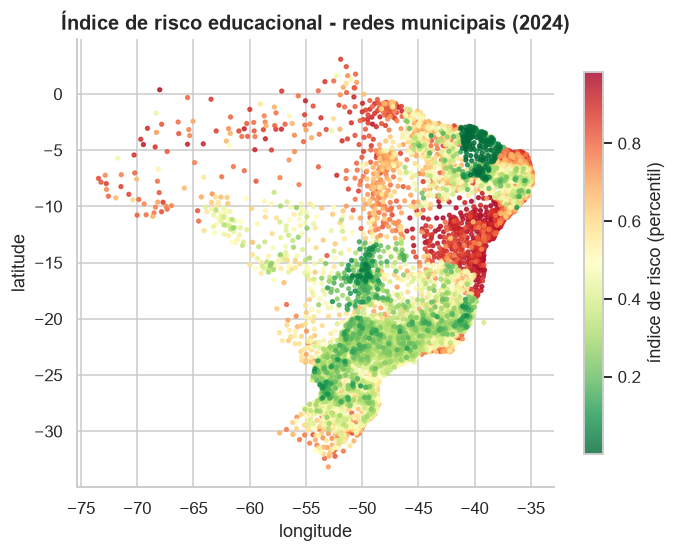

,redes no decil de maior risco,% das redes da UF
sigla_uf,,
BA,340.00,83.70
RN,45.00,30.00
PA,42.00,29.20
SE,31.00,43.10
AM,19.00,30.60
RJ,9.00,9.80
AL,8.00,7.80
PB,7.00,3.30
AC,4.00,18.20


In [11]:
decil_risco = estaveis[estaveis["indice_risco"] >= estaveis["indice_risco"].quantile(0.9)]
concentracao = pd.DataFrame({
    "redes no decil de maior risco": decil_risco["sigla_uf"].value_counts(),
    "% das redes da UF": (decil_risco["sigla_uf"].value_counts() / estaveis["sigla_uf"].value_counts() * 100),
}).dropna().sort_values("redes no decil de maior risco", ascending=False).round(1)

fig, ax = plt.subplots(figsize=(7, 7.5))
pontos = ax.scatter(estaveis["longitude"], estaveis["latitude"], c=estaveis["indice_risco"], cmap="RdYlGn_r",
                    s=6, alpha=0.8)
fig.colorbar(pontos, ax=ax, shrink=0.6, label="índice de risco (percentil)")
ax.set(title="Índice de risco educacional - redes municipais (2024)", xlabel="longitude", ylabel="latitude")
ax.set_aspect("equal")
fig.savefig(g.DIR_IMAGENS / "app_03_mapa_risco.png", bbox_inches="tight")
plt.show()

ranking[["id_municipio", *colunas_ranking, "risco_resultado", "risco_estrutural", "risco_meta", "desvio_vs_esperado"]] \
    .to_csv(DIR_REPORTS / "ranking_risco_municipios_2024.csv", index=False)
concentracao.head(10)

**Leitura:**
- **Esperado x real:** a maioria das redes fica perto da diagonal, onde o contexto explica o resultado. As que estão **muito abaixo** da linha têm resultado pior do que o contexto permitiria (problema de gestão). As que estão muito acima são referências (seção 3).
- **Concentração do risco:** o índice é muito concentrado na **Bahia**. 84% das redes baianas estão no decil de maior risco, que reúne resultado baixo, contexto desfavorável e baixa chance de atingir a meta. Também aparecem Sergipe (43%), Amazonas (31%), Rio Grande do Norte (30%) e Pará (29%).
- **Impacto absoluto:** em número de crianças não alfabetizadas, as grandes capitais dominam. Só a rede municipal de **São Paulo tem ~21,6 mil**, seguida por Rio (~15,7 mil), Manaus (~9,3 mil) e Salvador (~7,7 mil). São Paulo e Guarulhos alfabetizam **bem abaixo do que o contexto prevê** (48% contra 56% esperados; 44% contra 61%).
- **Duas listas, dois usos:** o índice de risco mostra **onde a situação é mais grave**; o número de crianças mostra **onde o investimento alcança mais crianças**. O arquivo `reports/ranking_risco_municipios_2024.csv` traz os componentes do índice de cada rede.

## 3. Quais regiões possuem padrões semelhantes?

Clusterização com **KMeans** sobre 12 variáveis de **contexto** (sem o resultado da prova),
padronizadas: trajetória escolar, nível socioeconômico, ruralidade, diversidade, infraestrutura,
docentes e porte. Depois comparamos o **resultado** de municípios com contexto parecido.

k,3,4,5,6,7,8
inercia,42556.51,39378.18,36653.04,34391.55,32720.55,31221.43
silhueta,0.23,0.15,0.15,0.15,0.16,0.16


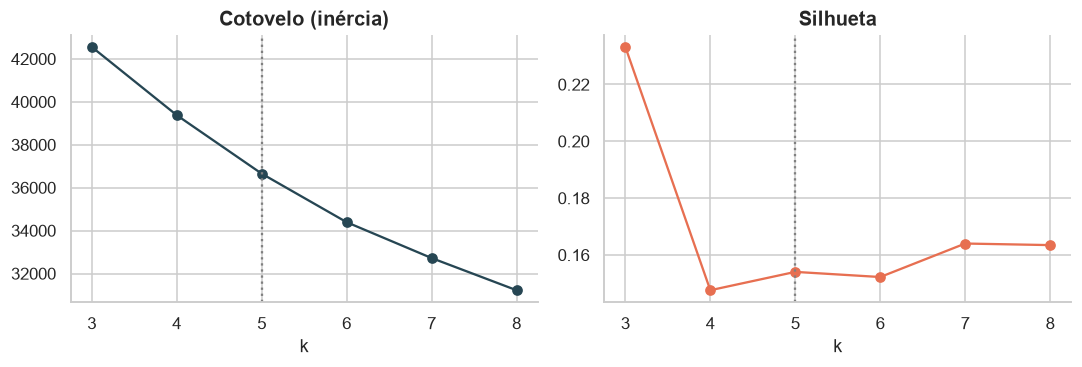

In [12]:
escolha_k = cl.avaliar_k(base_2024)
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5))
escolha_k["inercia"].plot(ax=eixos[0], marker="o", color=g.COR_PRINCIPAL, title="Cotovelo (inércia)")
escolha_k["silhueta"].plot(ax=eixos[1], marker="o", color=g.COR_DESTAQUE, title="Silhueta")
for ax in eixos:
    ax.axvline(5, color="grey", linestyle=":")
fig.tight_layout()
fig.savefig(g.DIR_IMAGENS / "app_04_escolha_k.png")
escolha_k.round(3).T

**Leitura:**
- **O que dizem os critérios:** a silhueta é maior com 3 grupos (0,23) e fica estável, em torno de 0,15, de 4 a 8. O cotovelo não tem uma quebra nítida. Isso é comum em dados socioeducacionais, que variam de forma contínua.
- **Por que k = 5:** com 3 grupos, as áreas indígenas, quilombolas e de assentamento se misturam com as redes rurais pobres. Com 5, elas formam um grupo próprio, essencial para política pública porque exigem estratégias específicas (material bilíngue, calendário diferenciado). A qualidade estatística é praticamente a mesma de k = 4 a 8.

In [13]:
K = 5
_, rotulos = cl.agrupar(base_2024, K)
base_2024["cluster"] = rotulos
nomes = cl.nomear_clusters(base_2024)
base_2024["grupo"] = base_2024["cluster"].map(nomes)

perfil = cl.perfil(base_2024, "grupo").sort_values("taxa de alfabetização (%)")
perfil.round(2).T

grupo,Vulnerável com fluxo escolar crítico,Áreas diferenciadas e rurais,Urbano de maior porte,Vulnerável com fluxo escolar regular,Pequenos municípios desenvolvidos
municípios,509,219,1030,1585,2107
taxa de alfabetização (%),41.93,50.00,59.31,62.86,70.51
% atingiu a meta do ano,33.05,47.83,50.91,56.33,57.47
região mais comum,Nordeste,Nordeste,Sudeste,Nordeste,Sudeste
distorção idade-série (%),16.40,8.60,4.30,6.10,2.90
abandono (%),1.90,0.50,0.10,0.20,0.00
INSE médio,4.40,4.36,5.20,4.42,5.19
pobreza infantil (%),55.80,61.00,12.18,56.68,17.24
IDHM,0.58,0.58,0.73,0.59,0.70
alunos em escola rural,0.41,0.54,0.04,0.35,0.00


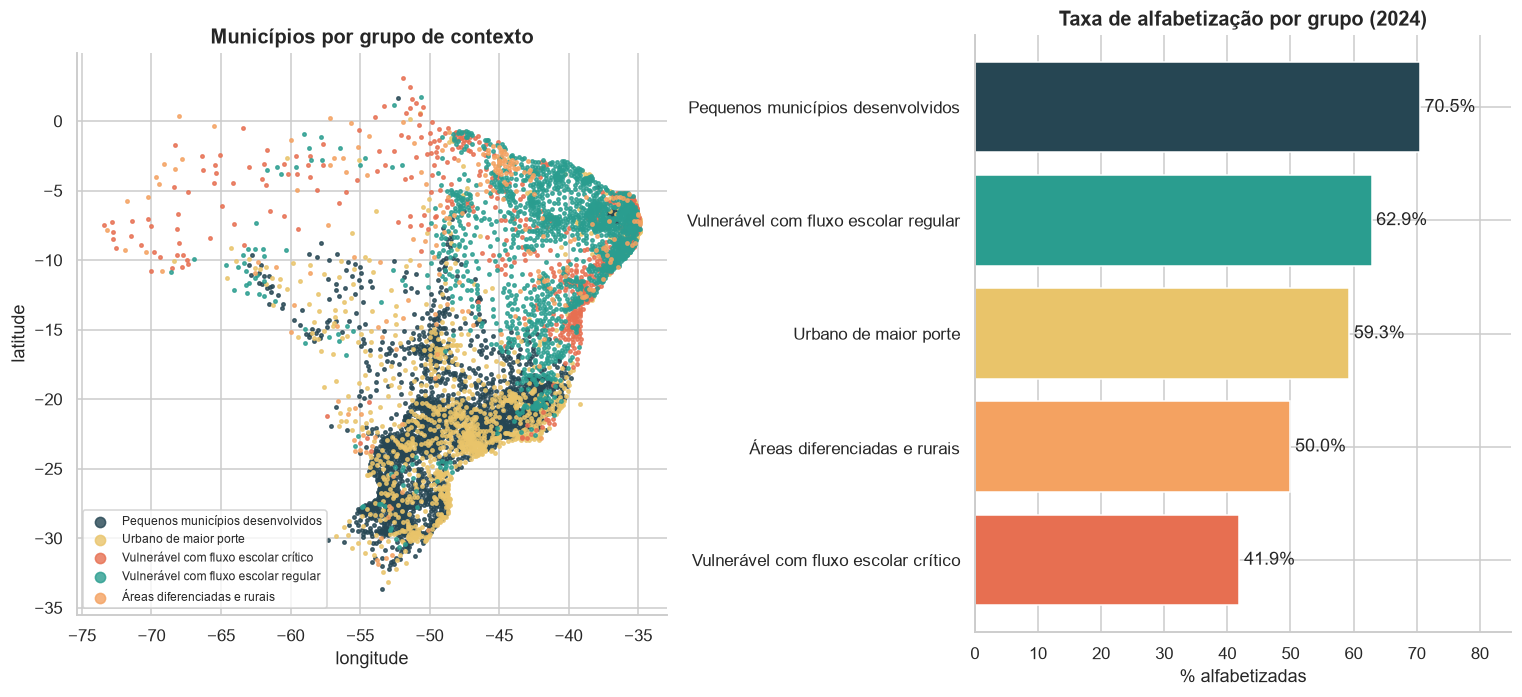

nome_regiao,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
grupo,,,,,
Vulnerável com fluxo escolar crítico,1.00,69.00,27.00,3.00,0.00
Áreas diferenciadas e rurais,15.00,54.00,23.00,3.00,5.00
Urbano de maior porte,15.00,7.00,4.00,47.00,27.00
Vulnerável com fluxo escolar regular,2.00,77.00,10.00,10.00,2.00
Pequenos municípios desenvolvidos,12.00,1.00,2.00,45.00,39.00


In [14]:
cores_grupo = dict(zip(perfil.index, ["#e76f51", "#f4a261", "#e9c46a", "#2a9d8f", "#264653"]))
fig, eixos = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
for grupo, dados in base_2024.groupby("grupo"):
    eixos[0].scatter(dados["longitude"], dados["latitude"], s=5, color=cores_grupo[grupo], label=grupo, alpha=0.8)
eixos[0].set(title="Municípios por grupo de contexto", xlabel="longitude", ylabel="latitude")
eixos[0].set_aspect("equal")
eixos[0].legend(loc="lower left", fontsize=8, markerscale=3)

barras = eixos[1].barh(perfil.index, perfil["taxa de alfabetização (%)"], color=[cores_grupo[i] for i in perfil.index])
eixos[1].bar_label(barras, fmt="%.1f%%", padding=3)
eixos[1].set(title="Taxa de alfabetização por grupo (2024)", xlabel="% alfabetizadas", xlim=(0, 85))
fig.tight_layout()
fig.savefig(g.DIR_IMAGENS / "app_05_clusters.png")
plt.show()

pd.crosstab(base_2024["grupo"], base_2024["nome_regiao"], normalize="index").mul(100).round(0).loc[perfil.index]

**Leitura - quais regiões possuem padrões semelhantes?**

| Grupo | Onde está | Taxa | Característica marcante |
|---|---|---|---|
| Pequenos municípios desenvolvidos | Sul/Sudeste | **71%** | baixa distorção, 100% com biblioteca, poucos alunos por docente |
| Vulnerável com fluxo regular | 77% Nordeste | **63%** | pobreza infantil de 57%, mas distorção de 6% e o maior tempo integral (20%) |
| Urbano de maior porte | Sudeste/Sul | **59%** | contexto favorável, mas resultado abaixo dos pequenos |
| Áreas diferenciadas e rurais | Nordeste/Norte | **50%** | 33% dos alunos em áreas indígenas, quilombolas ou de assentamento |
| Vulnerável com fluxo crítico | Nordeste/Norte | **42%** | distorção de 16%, abandono de 1,9%, só 35% com biblioteca |

**O achado principal:** os grupos *vulnerável com fluxo regular* e *vulnerável com fluxo crítico* têm a **mesma pobreza infantil (~56%) e o mesmo INSE (4,4)**, mas **21 pontos de diferença** na alfabetização. O que os separa é a trajetória escolar (distorção e abandono), a infraestrutura de leitura e a formação docente. São variáveis que a gestão pode mudar.

Outro ponto: as **grandes cidades** alfabetizam menos que os pequenos municípios desenvolvidos, mesmo com contexto parecido. Escala e complexidade da gestão também pesam.

### Referências dentro de cada grupo (desvio positivo)

Municípios que alfabetizam **muito acima do esperado** pelo seu contexto, comparados com os pares
do mesmo grupo. São candidatos naturais a estudo de caso e a intercâmbio de práticas.

In [15]:
base_2024["taxa_esperada_contexto"] = risco.taxa_esperada_contexto(base_2024)
base_2024["desvio_vs_esperado"] = base_2024["taxa_alfabetizacao"] - base_2024["taxa_esperada_contexto"]
referencias = (
    base_2024[(base_2024["alunos_avaliados"] >= 50) & (base_2024["participacao_2024"] >= 80)]
    .sort_values("desvio_vs_esperado", ascending=False)
    .groupby("grupo").head(3)
    .sort_values(["grupo", "desvio_vs_esperado"], ascending=[True, False])
    [["grupo", "nome_municipio", "sigla_uf", "alunos_avaliados", "participacao_2024", "taxa_alfabetizacao",
      "taxa_esperada_contexto", "desvio_vs_esperado"]]
)
base_2024[["id_municipio", "nome_municipio", "sigla_uf", "grupo", "taxa_alfabetizacao", "taxa_esperada_contexto",
           "desvio_vs_esperado", *cl.FEATURES_CLUSTER]].to_csv(DIR_REPORTS / "clusters_municipios.csv", index=False)
referencias.reset_index(drop=True)

,grupo,nome_municipio,sigla_uf,alunos_avaliados,participacao_2024,taxa_alfabetizacao,taxa_esperada_contexto,desvio_vs_esperado
0,Pequenos municípios desenvolvidos,Carlinda,MT,121,96.80,98.95,60.94,38.01
1,Pequenos municípios desenvolvidos,Nova União,MG,70,94.59,92.79,55.22,37.57
2,Pequenos municípios desenvolvidos,Bom Jesus do Amparo,MG,50,92.59,98.04,61.42,36.62
3,Urbano de maior porte,Corinto,MG,231,94.67,85.75,53.26,32.49
4,Urbano de maior porte,Denise,MT,82,94.25,83.60,55.78,27.82
5,Urbano de maior porte,Pedreira,SP,411,97.62,94.25,67.17,27.08
6,Vulnerável com fluxo escolar crítico,Tartarugalzinho,AP,269,91.50,94.22,43.73,50.49
7,Vulnerável com fluxo escolar crítico,Japurá,AM,77,80.21,91.93,47.32,44.61
8,Vulnerável com fluxo escolar crítico,Itaueira,PI,64,98.46,85.89,43.66,42.23
9,Vulnerável com fluxo escolar regular,Jequiá da Praia,AL,115,97.46,95.65,51.24,44.41


**Leitura:** em todos os grupos há redes que alfabetizam **30 a 50 pontos acima** do esperado pelo contexto, com participação de pelo menos 80% na prova. Alguns exemplos:
- **Tartarugalzinho (AP):** fluxo crítico, 94% de alfabetização contra 44% esperados.
- **Jequiá da Praia (AL) e Taperoá (PB):** vulnerável com fluxo regular.
- **Barreirinhas (MA):** áreas diferenciadas, com 762 alunos avaliados.

Esses municípios devem ser **estudados e visitados** por seus pares do mesmo grupo. Mostram que resultados altos são possíveis mesmo em contextos difíceis.

*Cuidado:* desvios muito grandes em redes pequenas também podem refletir particularidades da aplicação da prova. A recomendação é validar com as secretarias antes de transformar em referência oficial.

## 4. Respostas às perguntas de negócio e aplicação em políticas públicas

**Quais municípios apresentam maior risco educacional?**
Pelo índice de risco (resultado + contexto + chance de não atingir a meta), o risco é concentrado nas redes municipais da **Bahia** (84% delas no decil de maior risco), em **Sergipe, Rio Grande do Norte, Amazonas e Pará**. Em volume de crianças, as prioridades são as redes de **São Paulo, Rio de Janeiro, Manaus e Salvador**. São Paulo e Guarulhos estão bem abaixo do esperado para o seu contexto.

**Quais regiões possuem padrões semelhantes?**
Cinco perfis: pequenos municípios desenvolvidos (Sul/Sudeste), urbano de maior porte, vulnerável com fluxo regular (Nordeste), vulnerável com fluxo crítico (Nordeste/Norte) e áreas diferenciadas. Municípios com a **mesma pobreza** têm até **21 pontos** de diferença conforme o fluxo escolar.

**Como prever municípios que podem não atingir metas futuras?**
Com o modelo de transição (AUC de 0,59 a 0,81, conforme o cenário), com uma regra conservadora: nos estados com choque atípico no ano de treino (RS e MG), usa-se o cenário neutro. A previsão é que 54% das redes atinjam a meta de 2025, e 1.431 redes (27%) têm chance abaixo de 40%, concentradas na **Bahia**, onde o risco é estrutural. Cada previsão traz um nível de confiança.

### Como os modelos podem apoiar políticas públicas

1. **Priorização de apoio técnico e financeiro:** o ranking de risco orienta a distribuição de recursos do Compromisso Nacional Criança Alfabetizada. O índice prioriza gravidade; o número de crianças prioriza alcance.
2. **Alerta precoce de metas:** a previsão de 2025 identifica, **antes** da prova, as redes que precisam de reforço (formação de alfabetizadores, avaliação diagnóstica, material estruturado).
3. **Foco no fluxo escolar:** distorção idade-série e abandono são os fatores mais fortes e acionáveis. Busca ativa, acompanhamento de frequência e recomposição de aprendizagem nos anos iniciais.
4. **Regime de colaboração Estado-municípios:** o efeito do Ceará sugere que estados com política estruturada multiplicam o resultado. BA, SE, RN e TO, abaixo do esperado, são candidatos a programas desse tipo.
5. **Aprendizagem entre pares:** os grupos de contexto e as referências de desvio positivo permitem montar redes de intercâmbio entre municípios parecidos.
6. **Estratégias diferenciadas:** o grupo de áreas indígenas, quilombolas e de assentamento precisa de política específica, não apenas de mais recursos.